# Phase 3 — Exploratory Data Analysis (EDA)
## Patterns of Recorded Civilian Targeting in Gaza

**DS312 · Group 7 · Phase 3 notebook template**

This notebook continues from Phase 2. It first loads and checks the saved Phase 2 CSV outputs, then uses each table for the questions it can answer. The analysis moves from event-level descriptions to group comparisons, weekly patterns, and spatial exploration. Replace prompts with results from the saved project snapshot before submission.

> **Reading path:** project questions → Phase 2 CSVs and their roles → data checks → univariate → bivariate → grouped, temporal, and spatial analysis → hypothesis tests → key insights and Phase 4 plan.

## 3.1 Purpose, audience, and decision

### Purpose
Describe patterns, relationships, and unusual periods in the cleaned Gaza data. Use the evidence to refine the Phase 4 plan for spatial clustering and weekly anomaly detection.

### Audience and decision
The audience is human-rights documentation teams, civilian-protection analysts, investigative journalists, and research coordinators. The findings should help prioritize locations, periods, and incident groups for source verification and contextual investigation.

### Interpretation boundary
This notebook describes **recorded ACLED events**. The project focal-event flag is a reproducible coding rule, not proof of intent, responsibility, or legal classification.

### Narrative sequence
1. Read the Phase 2 outputs and confirm their units, dates, and intended use.
2. Describe individual variables before comparing groups.
3. Compare periods, event types, actors, and severity with explicit denominators.
4. Examine district-week and spatial patterns using the tables prepared for those units.
5. Test two exploratory hypotheses and use the results to refine Phase 4.

## 3.2 Phase 3 requirements and definition of done

This notebook is complete when it:

1. Uses the Phase 2 processed outputs and explains which table answers each question.
2. Includes univariate, bivariate, multivariate/grouped, temporal, and spatial exploration relevant to the business questions.
3. Presents **at least 8 purposeful visualizations**. Every figure has a question-led title, labeled axes/legend, and a 1–2 sentence interpretation.
4. States and tests **at least 2 hypotheses**, reporting test, assumptions/checks, p-value, effect size where appropriate, and a plain-language conclusion.
5. Includes **5–8 key insights** and a Phase 4 modeling plan grounded in the evidence.
6. Documents limitations and avoids causal language for observational associations.
7. Runs top-to-bottom reproducibly; paths, date parsing, and any filtering are explicit.

### Definition of done checklist
- [ ] Each chart answers a stated question and has an interpretation.
- [ ] Denominators match the event group, area, and period shown.
- [ ] Sparse categories and small expected test counts are handled transparently.
- [ ] Before/after period lengths and incomplete final week are acknowledged.
- [ ] EDA is exploratory; no future information is used to claim a predictive result.
- [ ] Findings link back to a Phase 1 business question.

## 3.3 Business questions guiding the analysis

Phase 1 established five questions. Phase 2 narrowed the working data to Gaza, so this notebook applies the questions within that scope. Before-and-after comparisons use the cleaned event master; post–October 7 temporal analysis uses the weekly CSVs; spatial exploration uses the land focal-incident CSV.

| ID | Question for Phase 3 | Main Phase 2 output | Phase 4 use |
|---|---|---|---|
| BQ1 | How do recorded focal-event counts and their share of political-violence events differ before and after October 7, 2023 in Gaza? | Cleaned event master | Descriptive baseline and sensitivity questions |
| BQ2 | Which recorded actors and event/sub-event types recur among focal events? | Cleaned event master | Interpretable event profiles; review notes before assigning roles |
| BQ3 | Where are post–October 7 land focal events concentrated, and how does precision affect the view? | Focal-incident table | DBSCAN settings and precision sensitivity |
| BQ4 | Which district-weeks show high or sustained focal activity relative to recent local history? | District-week and Gaza-week tables | Weekly anomaly features and baseline choices |
| BQ5 | Which patterns change under alternative periods, geography, or precision restrictions? | Relevant output table(s) | Robustness checks |

A planned question is not a result. Write each result only after the relevant table and plot have been reviewed.

## 3.4 Read the Phase 2 outputs before exploring them

Phase 2 saved four CSVs in `data/processed/`. They represent different populations and units. Load them in separate cells so it is clear which file supports each part of the analysis. Run this notebook from the project folder so the relative paths resolve.

| Phase 2 CSV | What one row represents | Use it for | Important scope note |
|---|---|---|---|
| `acled_events_clean.csv` | One Gaza event record, across both periods | Event-level variables, before/after comparisons, actor and event-type profiles, fatalities | Retains Gaza events, including coast-coded records and four records without a district. |
| `acled_gaza_week.csv` | One Gaza-wide calendar week after October 7 | Gaza-wide counts, shares, and temporal context | Zero-event weeks are present; final week may be incomplete; share is undefined with zero political events. |
| `acled_district_week.csv` | One known district and calendar week after October 7 | District comparisons, weekly persistence, heatmaps, lag features | District table excludes four records without `admin2`; use it only for district-level analysis. |
| `acled_focal_incidents.csv` | One post–October 7 land focal incident | Coordinate distribution and precision sensitivity | Coast-coded focal events are excluded for land spatial analysis; repeated coordinates are retained. |

The next cells load each file separately. Read the accompanying note before each cell; it explains why that output exists and what it can support.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")

# Run from the project root (the folder containing data/processed/).
DATA_DIR = Path("data/processed")
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_DIR.resolve()}. Run this notebook from the project root."
    )
print("Reading Phase 2 CSVs from:", DATA_DIR.resolve())

Reading Phase 2 CSVs from: C:\Users\marsh\Downloads\DMA-PIT\data\processed


### 3.4.1 Cleaned event master — `acled_events_clean.csv`

**Why this file:** it is the event-level Gaza master across the full download window. Use it for variable distributions, event/actor profiles, and the October 7 descriptive comparison. It is not the spatially restricted table.

**Read/check:** parse event, month, and week dates and restore precision codes as ordered categories; confirm the date span and inspect a few rows.

In [2]:
master = pd.read_csv(DATA_DIR / "acled_events_clean.csv", parse_dates=["event_date", "month_start", "week_start"])
for col in ("geo_precision", "time_precision"):
    master[col] = pd.Categorical(master[col], categories=[1, 2, 3], ordered=True)

print("Clean event master:", master.shape)
print("Event dates:", master.event_date.min().date(), "to", master.event_date.max().date())
display(master[["event_date", "period", "event_type", "fatalities", "focal_event", "admin2"]].head())

Clean event master: (26664, 43)
Event dates: 2022-01-01 to 2025-09-30


,event_date,period,event_type,fatalities,focal_event,admin2
0,2022-01-01,"Before Oct 7, 2023",Strategic developments,0,False,North Gaza
1,2022-01-01,"Before Oct 7, 2023",Strategic developments,0,False,Khan Yunis
2,2022-01-01,"Before Oct 7, 2023",Strategic developments,0,False,Deir El Balah
3,2022-01-01,"Before Oct 7, 2023",Strategic developments,0,False,Gaza City
4,2022-01-01,"Before Oct 7, 2023",Strategic developments,0,False,North Gaza


### 3.4.2 Gaza-wide weekly table — `acled_gaza_week.csv`

**Why this file:** Phase 2 aligned Gaza-wide event totals to a weekly calendar, including zero-record weeks. Use it to describe weekly counts and shares after October 7 and to inspect the available historical features.

**Read/check:** parse both week boundaries and review completeness, activity, and lag columns.

In [3]:
gaza_weekly = pd.read_csv(
    DATA_DIR / "acled_gaza_week.csv",
    parse_dates=["week_start", "week_end"],
)
print("Gaza-week table:", gaza_weekly.shape)
display(gaza_weekly[["week_start", "week_end", "complete_week", "political_events",
                     "focal_events", "focal_share", "previous_week_focal",
                     "previous_four_weeks_focal"]].head())

Gaza-week table: (104, 13)


,week_start,week_end,complete_week,political_events,focal_events,focal_share,previous_week_focal,previous_four_weeks_focal
0,2023-10-07,2023-10-13,True,234,139,0.594017,NaN,NaN
1,2023-10-14,2023-10-20,True,218,159,0.729358,139.0,NaN
2,2023-10-21,2023-10-27,True,289,203,0.702422,159.0,NaN
3,2023-10-28,2023-11-03,True,360,254,0.705556,203.0,NaN
4,2023-11-04,2023-11-10,True,365,233,0.638356,254.0,755.0


### 3.4.3 District-week table — `acled_district_week.csv`

**Why this file:** each row is a district-week built from records with a known district. Use it to compare district activity over the same calendar weeks and to explore eligible history. Do not substitute it for the Gaza-wide table.

**Read/check:** parse week boundaries and verify the district and week fields before building grouped views.

In [4]:
district_weekly = pd.read_csv(
    DATA_DIR / "acled_district_week.csv",
    parse_dates=["week_start", "week_end"],
)
print("District-week table:", district_weekly.shape)
print("Districts:", district_weekly.admin2.nunique(),
      "| weeks:", district_weekly.week_start.nunique())
display(district_weekly[["admin2", "week_start", "complete_week", "political_events",
                         "focal_events", "focal_share", "history_eligible"]].head())

District-week table: (520, 14)
Districts: 5 | weeks: 104


,admin2,week_start,complete_week,political_events,focal_events,focal_share,history_eligible
0,Deir El Balah,2023-10-07,True,31,17,0.548387,True
1,Deir El Balah,2023-10-14,True,30,21,0.700000,True
2,Deir El Balah,2023-10-21,True,46,34,0.739130,True
3,Deir El Balah,2023-10-28,True,51,44,0.862745,True
4,Deir El Balah,2023-11-04,True,55,36,0.654545,True


### 3.4.4 Land focal-incident table — `acled_focal_incidents.csv`

**Why this file:** Phase 2 prepared post–October 7 focal events for land-based spatial analysis and added coordinates in radians for later haversine clustering. Use the degree coordinates for maps and the precision fields for sensitivity views.

**Read/check:** parse event, month, and week dates, restore precision categories, then inspect coordinate ranges and repeated locations.

In [5]:
incidents = pd.read_csv(
    DATA_DIR / "acled_focal_incidents.csv",
    parse_dates=["event_date", "month_start", "week_start"],
)
for col in ("geo_precision", "time_precision"):
    incidents[col] = pd.Categorical(incidents[col], categories=[1, 2, 3], ordered=True)
print("Land focal incidents:", incidents.shape)
print("Distinct coordinate pairs:", len(incidents[["latitude", "longitude"]].drop_duplicates()))
print("Precision 1 records:", incidents.geo_precision_1.sum())
display(incidents[["event_date", "location", "latitude", "longitude",
                   "geo_precision", "geo_precision_1"]].head())

Land focal incidents: (10583, 45)
Distinct coordinate pairs: 101
Precision 1 records: 7576


,event_date,location,latitude,longitude,geo_precision,geo_precision_1
0,2023-10-07,Khan Yunis - West (Municipal Stadium),31.3484,34.2961,1,True
1,2023-10-07,Gaza - Shujaiyya,31.4988,34.4699,1,True
2,2023-10-07,Gaza - Unspecified,31.5045,34.4743,2,False
3,2023-10-07,Gaza - Northern Remal,31.5240,34.4505,1,True
4,2023-10-07,Bani Suheila,31.3424,34.3250,2,False


### 3.4.5 Loading summary and transition to EDA

The files are now loaded as `master`, `gaza_weekly`, `district_weekly`, and `incidents`. The following audit checks expected fields and key scope facts before charts are made. After that, each EDA section names the table it uses so readers can trace every result back to a Phase 2 output.

## 3.5 Data contract: variables, units, and roles

Use this as the minimum variable contract. Add or remove variables only with a written reason tied to a business question.

| Variable(s) | Type / role in EDA | Use | Handling note |
|---|---|---|---|
| `event_date`, `period`, `month_start`, `week_start` | Date / grouping | Before-after, monthly and weekly trends | Periods differ in duration; compare rates/shares as well as counts. |
| `focal_event` | Boolean outcome for description | Numerator in focal counts and shares | Project-derived rule from targeting flag and exact civilian actor label. |
| `political_violence` | Boolean denominator group | Context and denominator for focal share | Exact token matching was used in Phase 2. |
| `targeting_flagged`, `civilian_targeting` | Boolean / source category | Describe ACLED targeting coding | Blank source value is preserved; derived boolean means recorded flag present. |
| `actor1`, `actor2`, `event_type`, `sub_event_type`, `disorder_type` | Categorical | Actor/event profiles and cross-tabs | Actor labels are high-cardinality; show top groups plus an “Other” display bucket only if documented. |
| `fatalities`, `fatalities_log1p`, `high_fatalities_review` | Count / derived review flag | Severity distribution and comparisons | Retain raw counts; review flags do not mean invalid records. |
| `admin2`, `location` | Geographic categories | District summaries and location descriptions | Four events have missing district; exclude only when district is required. |
| `latitude`, `longitude`, `geo_precision`, `geo_precision_1` | Coordinates / quality | Spatial distribution and sensitivity | Preserve geographic geometry; precision codes are categories, not distances. |
| `time_precision`, `time_precision_1` | Quality category / flag | Sensitivity checks | Do not interpret code values as continuous measurements. |
| `recorded_events`, `political_events`, `focal_events`, `focal_share` | Weekly aggregates | Trends and district-week comparisons | `focal_share` is undefined when denominator is zero. |
| `previous_week_focal`, `previous_four_weeks_focal`, `history_eligible` | Historical features | Explore candidate Phase 4 predictors/baselines | Lagged by Phase 2; use only prior weeks for an alerting feature. |

### Basic integrity review


In [6]:
# Check the loaded Phase 2 tables before plotting or comparing groups.
required = {
    "master": {"event_date", "period", "event_type", "actor1", "fatalities", "focal_event", "political_violence", "admin2"},
    "gaza_weekly": {"week_start", "week_end", "political_events", "focal_events", "focal_share", "complete_week"},
    "district_weekly": {"admin2", "week_start", "focal_events", "political_events", "focal_share", "history_eligible"},
    "incidents": {"event_date", "location", "latitude", "longitude", "geo_precision", "geo_precision_1"},
}
frames = {"master": master, "gaza_weekly": gaza_weekly,
          "district_weekly": district_weekly, "incidents": incidents}
for name, cols in required.items():
    missing_cols = cols - set(frames[name].columns)
    print(name, "missing expected columns:", sorted(missing_cols))

print("\nEvent-level coverage and missing districts")
print("Missing admin2:", master.admin2.isna().sum())
print("\nFocal-event records by period")
display(master.groupby("period", dropna=False).focal_event.agg(["size", "sum", "mean"]))
print("\nTable shapes:")
for name, frame in frames.items():
    print(f"{name}: {frame.shape}")

master missing expected columns: []
gaza_weekly missing expected columns: []
district_weekly missing expected columns: []
incidents missing expected columns: []

Event-level coverage and missing districts
Missing admin2: 4

Focal-event records by period


,size,sum,mean
period,,,
"Before Oct 7, 2023",2254,63,0.027950
"Oct 7, 2023 onward",24410,10651,0.436338



Table shapes:
master: (26664, 43)
gaza_weekly: (104, 13)
district_weekly: (520, 14)
incidents: (10583, 45)


## 3.6 Analysis plan and visualization backlog

Complete the “Question / result / interpretation” prompts under each figure. The 10 candidate visuals below give options; select at least 8 and retain only those that reveal something relevant.

| ID | Level | Question and variables | Suggested visual | Requirement / caution |
|---|---|---|---|---|
| V1 | Univariate | What is the distribution of reported fatalities? `fatalities` | Histogram or ECDF; optionally side-by-side with `fatalities_log1p` | Show zeros and long tail; do not delete flagged high counts. |
| V2 | Univariate | Which event types dominate? `event_type` | Ordered count bar chart | Include counts and shares. |
| V3 | Univariate | Which actors recur in focal events? `actor1` / `actor2` | Top-actor bar chart | Explain missing actor2 as structural where applicable; actor labels are coding, not verified roles. |
| V4 | Bivariate | Does focal-event share differ by period? `period`, `focal_event`, `political_violence` | Period rate plot with numerator and denominator | Use political-violence records as denominator; show raw counts too. |
| V5 | Bivariate | Which event types have more focal events? `event_type`, `focal_event` | Grouped/stacked bars or rate chart | Counts can reflect different event-type volumes; include within-type percentages. |
| V6 | Bivariate | How does severity vary by focal status/type? `fatalities`, `focal_event`, `event_type` | Box/violin or ECDF | Heavy skew; show median/IQR or log view and sample sizes. |
| V7 | Multivariate | Which districts have persistent high weeks? `admin2`, `week_start`, `focal_events` | District-week heatmap | Mark zero weeks and report missing-district scope. |
| V8 | Temporal | How do Gaza-wide weekly counts and shares change? `focal_events`, `political_events`, `focal_share` | Line plots with clear denominator/units | Mark incomplete last week; share undefined at zero denominator. |
| V9 | Spatial | Where are land focal incidents recorded? `latitude`, `longitude` | Map/scatter density view | Discuss repeated coordinates and location precision; no inferred borders. |
| V10 | Sensitivity | How does the spatial pattern change for precision 1? `geo_precision_1`, coordinates | Side-by-side map or density plot | Same extent and symbols; describe coverage loss as well as pattern. |

For each visualization include a short Markdown interpretation: **what is visible, how strong/stable it appears, and why it matters for the business question**.

## 3.7 Reusable plotting helpers (optional)

The course guide does not require generic univariate, bivariate, or multivariate EDA functions. It requires purposeful analysis, at least eight interpreted visualizations, two tested hypotheses, and a closing modeling plan. Its reusable-pipeline example appears in the advanced Phase 2 cleaning criteria.

A few small plotting helpers can keep styles consistent. Keep filters, denominators, test choices, and interpretation visible in the analysis cells; each chart still needs its own written interpretation.

In [7]:
def plot_count(data, column, *, title, order=None, ax=None, normalize=False):
    """Count plot for one categorical variable; normalize=True shows within-column shares."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5))
    counts = data[column].value_counts(dropna=False, normalize=normalize)
    if order is not None:
        counts = counts.reindex(order).dropna()
    counts.sort_values().plot(kind="barh", ax=ax, color="#315A7D")
    ax.set_title(title)
    ax.set_xlabel("Share of records" if normalize else "Number of records")
    ax.set_ylabel(column.replace("_", " ").title())
    return ax


def plot_numeric(data, column, *, title, bins=30, log_x=False, ax=None):
    """Histogram for a numeric variable; choose log_x only when the scale is meaningful."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5))
    values = data[column].dropna()
    ax.hist(values, bins=bins, color="#4B8A78", edgecolor="white")
    if log_x:
        ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of records")
    return ax

## 3.8 Univariate analysis — what does each field look like?

**Source table:** `master` for event-level fields. Use `gaza_weekly` for the weekly distribution and `incidents` only for spatial-input quality. Begin with the distribution of each variable before asking what differs between groups.

Report counts/shares for categories and robust summaries for skewed counts. Show fatalities both as recorded and in the `log1p` display. Do not interpret precision codes as continuous measurements.

In [8]:
# Shared labels for summaries and figures in the univariate section.
BLUE, GREEN, RED, GREY = "#315A7D", "#4B8A78", "#8D3B42", "#8A8F98"
BEFORE, AFTER = "Before Oct 7, 2023", "Oct 7, 2023 onward"
cutoff = pd.Timestamp("2023-10-07")

### 3.8.1 Summary profiles of variables

**Question:** what does each column hold, how complete is it, and which summary fits its type?

The profile reports each included column's type group, missing count and percentage, number of distinct non-missing values, and a type-appropriate summary. Continuous/count variables receive min/median/mean/max; categorical variables receive their mode; Boolean flags receive the share of `True`; and dates receive their range. Precision codes are categories, while `year` and `iso` are identifiers/categories rather than measurements. The Unix `timestamp` is treated as a record-update timestamp, not as an event date.

The event master and both weekly tables are profiled across all columns. For the land focal-incident table, the profile is intentionally limited to the spatial and precision fields relevant to the next phase; it is not a full profile of all 45 columns.


In [9]:
def profile_table(frame, categorical_columns=None, timestamp_columns=None):
    """Profile columns with summaries appropriate to their meaning and dtype."""
    categorical_columns = set(categorical_columns or [])
    timestamp_columns = set(timestamp_columns or [])
    rows = []

    for col in frame.columns:
        s = frame[col]
        n_missing = int(s.isna().sum())
        distinct = int(s.nunique(dropna=True))
        non_missing = int(s.notna().sum())

        if col in timestamp_columns:
            dt = pd.to_datetime(s, unit="s", errors="coerce", utc=True)
            kind = "record timestamp (UTC)"
            summary = (f"{dt.min().date()} to {dt.max().date()}"
                       if dt.notna().any() else "no valid timestamps")
        elif col in categorical_columns:
            kind = "identifier / category"
            if non_missing == 0:
                summary = "all values missing"
            elif distinct == non_missing:
                summary = "unique in every non-missing row"
            else:
                counts = s.value_counts(dropna=True)
                summary = f"mode = {str(counts.index[0])[:38]} ({counts.iloc[0] / non_missing:.1%})"
        elif pd.api.types.is_bool_dtype(s):
            kind = "boolean"
            summary = f"True = {s.mean():.1%}" if non_missing else "all values missing"
        elif isinstance(s.dtype, pd.CategoricalDtype):
            kind = "ordered category"
            counts = s.value_counts(dropna=True)
            summary = (f"mode = {counts.index[0]} ({counts.iloc[0] / non_missing:.1%})"
                       if non_missing else "all values missing")
        elif pd.api.types.is_datetime64_any_dtype(s):
            kind = "date"
            summary = f"{s.min().date()} to {s.max().date()}" if non_missing else "all values missing"
        elif pd.api.types.is_numeric_dtype(s):
            kind = "numeric"
            summary = (f"min {s.min():.6g} | median {s.median():.6g} | "
                       f"mean {s.mean():.6g} | max {s.max():.6g}"
                       if non_missing else "all values missing")
        else:
            kind = "text / category"
            if non_missing == 0:
                summary = "all values missing"
            elif distinct == non_missing:
                summary = "unique in every non-missing row"
            else:
                counts = s.value_counts(dropna=True)
                summary = f"mode = {str(counts.index[0])[:38]} ({counts.iloc[0] / non_missing:.1%})"

        rows.append({
            "Column": col, "Kind": kind, "Missing": n_missing,
            "Missing (%)": round(100 * n_missing / len(s), 2) if len(s) else np.nan,
            "Distinct": distinct, "Summary": summary
        })

    return pd.DataFrame(rows).set_index("Column")


# These columns are numeric in storage but represent labels/identifiers.
MASTER_CATEGORICAL = {"year", "iso"}
WEEKLY_CATEGORICAL = {"year", "week", "iso"}
master_profile = profile_table(
    master, categorical_columns=MASTER_CATEGORICAL, timestamp_columns={"timestamp"}
)
print(f"Event master: {master.shape[0]:,} rows x {master.shape[1]} columns")
display(master_profile)


Event master: 26,664 rows x 43 columns


,Kind,Missing,Missing (%),Distinct,Summary
Column,,,,,
event_id_cnty,text / category,0,0.00,26664,unique in every non-missing row
event_date,date,0,0.00,1300,2022-01-01 to 2025-09-30
year,identifier / category,0,0.00,4,mode = 2024 (48.1%)
time_precision,ordered category,0,0.00,3,mode = 1 (99.2%)
disorder_type,text / category,0,0.00,4,mode = Political violence (85.3%)
event_type,text / category,0,0.00,6,mode = Explosions/Remote violence (76.0%)
sub_event_type,text / category,0,0.00,21,mode = Air/drone strike (46.3%)
actor1,text / category,0,0.00,34,mode = Military Forces of Israel (2022-) (81.1%)
assoc_actor_1,text / category,25789,96.72,143,mode = PIJ: Palestinian Islamic Jihad (22.6%)


In [10]:
print("Gaza-wide weekly table")
display(profile_table(gaza_weekly, categorical_columns=WEEKLY_CATEGORICAL))
print("\nDistrict-week table")
display(profile_table(district_weekly, categorical_columns=WEEKLY_CATEGORICAL))
spatial_fields = ["latitude", "longitude", "latitude_rad", "longitude_rad", "geo_precision",
                  "geo_precision_1", "time_precision", "location", "admin2", "coastal_location"]
print("\nLand focal incidents (selected spatial fields only; not all 45 columns)")
display(profile_table(incidents[spatial_fields], categorical_columns={"location", "admin2"}))


Gaza-wide weekly table


,Kind,Missing,Missing (%),Distinct,Summary
Column,,,,,
admin1,text / category,0,0.00,1,mode = Gaza Strip (100.0%)
week_start,date,0,0.00,104,2023-10-07 to 2025-09-27
recorded_events,numeric,0,0.00,77,min 23 | median 238.5 | mean 234.712 | max 367
political_events,numeric,0,0.00,77,min 22 | median 214 | mean 215.038 | max 365
focal_events,numeric,0,0.00,67,min 15 | median 97.5 | mean 102.413 | max 254
week_end,date,0,0.00,104,2023-10-13 to 2025-10-03
complete_week,boolean,0,0.00,2,True = 99.0%
political_activity_recorded,boolean,0,0.00,1,True = 100.0%
focal_share,numeric,0,0.00,101,min 0.295302 | median 0.475229 | mean 0.485999...



District-week table


,Kind,Missing,Missing (%),Distinct,Summary
Column,,,,,
admin1,text / category,0,0.00,1,mode = Gaza Strip (100.0%)
admin2,text / category,0,0.00,5,mode = Deir El Balah (20.0%)
week_start,date,0,0.00,104,2023-10-07 to 2025-09-27
recorded_events,numeric,0,0.00,112,min 0 | median 42 | mean 46.9346 | max 157
political_events,numeric,0,0.00,104,min 0 | median 39 | mean 43 | max 156
focal_events,numeric,0,0.00,67,min 0 | median 19 | mean 20.4769 | max 102
week_end,date,0,0.00,104,2023-10-13 to 2025-10-03
complete_week,boolean,0,0.00,2,True = 99.0%
political_activity_recorded,boolean,0,0.00,2,True = 99.4%



Land focal incidents (selected spatial fields only; not all 45 columns)


,Kind,Missing,Missing (%),Distinct,Summary
Column,,,,,
latitude,numeric,0,0.0,100,min 31.2431 | median 31.4486 | mean 31.4351 | ...
longitude,numeric,0,0.0,101,min 34.2299 | median 34.3925 | mean 34.3876 | ...
latitude_rad,numeric,0,0.0,100,min 0.545295 | median 0.548882 | mean 0.548646...
longitude_rad,numeric,0,0.0,101,min 0.597424 | median 0.600262 | mean 0.600177...
geo_precision,ordered category,0,0.0,3,mode = 1 (71.6%)
geo_precision_1,boolean,0,0.0,2,True = 71.6%
time_precision,ordered category,0,0.0,3,mode = 1 (99.6%)
location,identifier / category,0,0.0,101,mode = Gaza - Az Zaytun (4.6%)
admin2,identifier / category,0,0.0,5,mode = Gaza City (32.5%)


In [11]:
# Free-text and identifier columns: describe length and cardinality rather than a "distribution".
tags_split = master.tags.dropna().str.split(";").explode().str.strip()
text_summary = pd.DataFrame({
    "notes (characters)": master.notes.str.len().describe(percentiles=[.5, .95]).round(0),
}).T
display(text_summary)
print("Distinct source strings:", master.source.nunique(), "| distinct locations:", master.location.nunique())
print("\nsource_scale (top 6):")
display(master.source_scale.value_counts().head(6).rename("records").to_frame())
print("\nIndividual tag labels (a record can carry several; tags is blank for", master.tags.isna().sum(), "records):")
display(tags_split.value_counts().head(8).rename("records").to_frame())
print("\nrecord timestamp (Unix seconds, converted):",
      pd.to_datetime(master.timestamp, unit="s").min().date(), "to",
      pd.to_datetime(master.timestamp, unit="s").max().date())

,count,mean,std,min,50%,95%,max
notes (characters),26664.0,219.0,109.0,88.0,183.0,422.0,1578.0


Distinct source strings: 1504 | distinct locations: 117

source_scale (top 6):


,records
National,11251
New media-National,6823
Other,3145
Other-New media,1390
Other-National,1353
Local partner-New media,1079



Individual tag labels (a record can carry several; tags is blank for 333 records):


,records
Foreign military engagement,25865
Atrocity,1402
Terrorist activity,429
crowd size=small,345
crowd size=medium,43
local administrators,22
crowd size=large,17
Repression,10



record timestamp (Unix seconds, converted): 2024-05-13 to 2026-10-05


**Result.** The event master has 43 columns (30 source fields after dropping the empty `admin3`, plus 13 fields derived in Phase 2). Seven columns contain missing values: `assoc_actor_1` (96.7%), `assoc_actor_2` (81.9%), `civilian_targeting` (59.8%), `actor2` and `inter2` (32.4% each), `tags` (1.2%) and `admin2` (4 records, 0.02%). Four columns are constant (`iso`, `region`, `country`, `admin1`) and add no variation within this Gaza-only extract. `civilian_targeting` has a single non-blank label, so it behaves like a recorded flag. The weekly tables contain missing history features at positions where the required prior history is unavailable; district-week focal shares are undefined when the political-violence denominator is zero.

**Meaning.** Missingness is not automatically a data-entry error. `actor2`/`inter2` blanks are structural single-sided interactions, while a blank `civilian_targeting` means ACLED did not record a value for that field. Phase 2 left these values unfilled; downstream analysis should preserve that distinction rather than silently replacing blanks with zero.

**Limit.** `notes` has 26,655 distinct strings for 26,664 records, so a few narratives repeat; event IDs are unique and Phase 2 found no duplicate rows. `timestamp` is ACLED's Unix record-update timestamp, not the event date, and should not be interpreted as when an event occurred. The profile treats `year` and `iso` as labels rather than computing potentially misleading averages.


**Free-text and identifier fields.** `notes` is a narrative (median 183 characters, 95th percentile 422, maximum 1,578), `source` has 1,504 distinct strings (many records cite several outlets joined by `;`), and `tags` can hold several labels per record. These are not analyzed as distributions. They matter as evidence: Phase 4 recommendations should link back to `event_id_cnty`, `notes`, and `source` for verification.

### 3.8.2 Fatalities: `fatalities`, `fatalities_log1p`, and the review flag

**Question:** how many reported fatalities does a typical event record carry, and how heavy is the tail?
`fatalities` is the reported total for the whole event record, a count with many zeros and a long right tail, so the mean alone is misleading. We report the median, quartiles, and the 90th/95th/99th percentiles, show a pooled bar chart for small values, an ECDF on a symmetric-log axis, and the `log1p` view that Phase 2 saved for display. The `high_fatalities_review` flag (> 23, the full-export 99th percentile) is a review aid; no event is removed.

In [12]:
f = master.fatalities
REVIEW_THRESHOLD = int(master.loc[~master.high_fatalities_review, "fatalities"].max())
assert master.loc[master.high_fatalities_review, "fatalities"].min() > REVIEW_THRESHOLD

pct_labels = [.5, .75, .9, .95, .99]
fat_summary = pd.Series({
    "Records": len(f),
    "Total reported fatalities": f.sum(),
    "Mean": f.mean(),
    "Median": f.median(),
    "Q1 / Q3": f"{f.quantile(.25):.0f} / {f.quantile(.75):.0f}",
    "P90": f.quantile(.90),
    "P95": f.quantile(.95),
    "P99 (Gaza)": f.quantile(.99),
    "Maximum": f.max(),
    "Records with 0 fatalities": f"{(f == 0).sum():,} ({(f == 0).mean():.1%})",
    "Median among records with 1+": f[f > 0].median(),
    "Mean among records with 1+": round(f[f > 0].mean(), 2),
}).to_frame("fatalities")
display(fat_summary)

log_summary = master.fatalities_log1p.describe(percentiles=[.5, .9, .99]).round(3).to_frame("fatalities_log1p")
display(log_summary.T)

flagged = master[master.high_fatalities_review]
gaza_p99 = f.quantile(.99)
review = pd.Series({
    "Review threshold (full-export P99, from Phase 2)": f"> {REVIEW_THRESHOLD}",
    "Flagged records": f"{len(flagged):,} ({len(flagged) / len(master):.1%})",
    "Share of all reported fatalities in flagged records": f"{flagged.fatalities.sum() / f.sum():.1%}",
    "Flagged records before Oct 7, 2023": int((flagged.period == BEFORE).sum()),
    "Records above the Gaza-only P99 (comparison)": f"{(f > gaza_p99).sum():,} (P99 = {gaza_p99:.0f})",
}).to_frame("value")
display(review)
display(master.nlargest(5, "fatalities")[["event_id_cnty", "event_date", "location", "sub_event_type", "fatalities"]])

,fatalities
Records,26664
Total reported fatalities,68012
Mean,2.550705
Median,0.0
Q1 / Q3,0 / 2
P90,7.0
P95,12.0
P99 (Gaza),39.0
Maximum,471
Records with 0 fatalities,"17,634 (66.1%)"


,count,mean,std,min,50%,90%,99%,max
fatalities_log1p,26664.0,0.569,0.938,0.0,0.0,2.079,3.689,6.157


,value
"Review threshold (full-export P99, from Phase 2)",> 23
Flagged records,576 (2.2%)
Share of all reported fatalities in flagged records,37.6%
"Flagged records before Oct 7, 2023",0
Records above the Gaza-only P99 (comparison),262 (P99 = 39)


,event_id_cnty,event_date,location,sub_event_type,fatalities
2615,PSE37743,2023-10-17,Gaza - Az Zaytun,Air/drone strike,471
3030,PSE39856,2023-10-28,Gaza - Nasr,Air/drone strike,299
4095,PSE41414,2023-11-18,Jabalya Camp,Air/drone strike,232
5648,PSE44041,2023-12-26,Jabalya,Air/drone strike,162
3714,PSE40702,2023-11-10,Gaza - Ash Shati' Camp,Armed clash,150


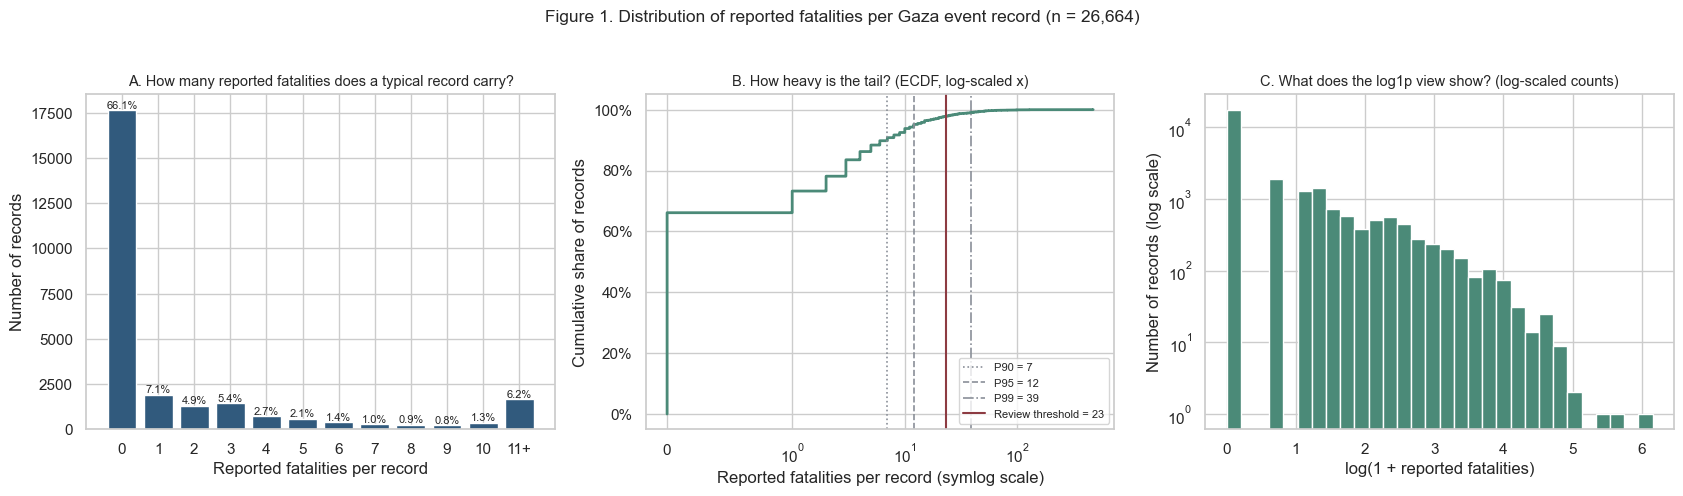

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# exact counts for small values, with a pooled 11+ bar
vc = f.clip(upper=11).value_counts().sort_index()
axes[0].bar([str(i) if i < 11 else "11+" for i in vc.index], vc.values, color=BLUE)
for x, v in enumerate(vc.values):
    axes[0].text(x, v, f"{v / len(f):.1%}", ha="center", va="bottom", fontsize=8)
axes[0].set_title("A. How many reported fatalities does a typical record carry?", fontsize=10.5)
axes[0].set_xlabel("Reported fatalities per record")
axes[0].set_ylabel("Number of records")

# ECDF on a symmetric-log x-axis
x = np.sort(f.to_numpy())
y = np.arange(1, len(x) + 1) / len(x)
axes[1].step(x, y, where="post", color=GREEN, lw=2)
axes[1].set_xscale("symlog", linthresh=1)
for q, ls in zip([.90, .95, .99], [":", "--", "-."]):
    axes[1].axvline(f.quantile(q), color=GREY, ls=ls, lw=1.2, label=f"P{int(q * 100)} = {f.quantile(q):.0f}")
axes[1].axvline(REVIEW_THRESHOLD, color=RED, lw=1.5, label=f"Review threshold = {REVIEW_THRESHOLD}")
axes[1].set_title("B. How heavy is the tail? (ECDF, log-scaled x)", fontsize=10.5)
axes[1].set_xlabel("Reported fatalities per record (symlog scale)")
axes[1].set_ylabel("Cumulative share of records")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend(fontsize=8, loc="lower right")

axes[2].hist(master.fatalities_log1p, bins=30, color=GREEN, edgecolor="white")
axes[2].set_yscale("log")
axes[2].set_title("C. What does the log1p view show? (log-scaled counts)", fontsize=10.5)
axes[2].set_xlabel("log(1 + reported fatalities)")
axes[2].set_ylabel("Number of records (log scale)")

fig.suptitle("Figure 1. Distribution of reported fatalities per Gaza event record (n = 26,664)", fontsize=12.5, y=1.03)
plt.tight_layout()
plt.show()

**Question.** How many reported fatalities does a record carry, and how heavy is the tail?
**Result.** Two out of three records (17,634; 66.1%) report zero fatalities and the median is 0 (Q1/Q3 = 0/2). Among the 9,030 records with at least one, the median is 3 but the mean is 7.53. The percentiles climb steeply: P90 = 7, P95 = 12, P99 = 39, maximum 471 (air/drone strike, Gaza – Az Zaytun, October 17, 2023). The 576 flagged records (2.2%) hold 37.6% of all 68,012 reported fatalities, and all of them occur on or after October 7, 2023. Using the Gaza-only P99 (39) instead of the Phase 2 threshold (23) would flag 262 records.
**Meaning.** Fatalities are zero-inflated and heavy-tailed, so means and standard deviations (mean 2.55, SD 8.50) describe a distribution that almost no record resembles. Later comparisons should use medians, IQR, percentiles, or `log1p`, and say how many records sit in the zero class.
**Limit.** Totals describe the whole event record, not the number of civilians killed, and the largest values should be checked against `notes` and `source` before being quoted.

### 3.8.3 Event categories: `event_type`, `sub_event_type`, `disorder_type`

**Question:** which recorded event types dominate, and are the categories large enough to compare later?
We report counts and shares of all 26,664 records. Sub-event types nest inside event types (checked by assertion), and `disorder_type` can hold two labels in one record, so we keep the recorded value and report the `political_violence` flag separately.

In [14]:
def count_table(series, total=None):
    total = total or len(series)
    out = series.value_counts(dropna=False).rename("Records").to_frame()
    out["Share (%)"] = (100 * out.Records / total).round(2)
    return out

print("event_type")
display(count_table(master.event_type))
print("\nsub_event_type (with its parent event_type)")
parent = master.groupby("sub_event_type").event_type.agg(["nunique", "first"])
assert (parent["nunique"] == 1).all(), "A sub_event_type maps to more than one event_type."
sub_tbl = count_table(master.sub_event_type)
sub_tbl.insert(0, "Parent event_type", parent["first"].reindex(sub_tbl.index))
display(sub_tbl)

print("\ndisorder_type (multi-label values kept as recorded)")
display(count_table(master.disorder_type))
both = master.disorder_type.str.contains(";", na=False).sum()
print(f"Records carrying two disorder labels: {both}")
print(f"political_violence flag (token match): {master.political_violence.sum():,} "
      f"({master.political_violence.mean():.1%} of records)")

event_type


,Records,Share (%)
Explosions/Remote violence,20276,76.04
Strategic developments,3517,13.19
Battles,1648,6.18
Violence against civilians,814,3.05
Protests,330,1.24
Riots,79,0.30



sub_event_type (with its parent event_type)


,Parent event_type,Records,Share (%)
Air/drone strike,Explosions/Remote violence,12357,46.34
Shelling/artillery/missile attack,Explosions/Remote violence,7617,28.57
Other,Strategic developments,1663,6.24
Armed clash,Battles,1647,6.18
Looting/property destruction,Strategic developments,1509,5.66
Attack,Violence against civilians,798,2.99
Peaceful protest,Protests,318,1.19
Change to group/activity,Strategic developments,301,1.13
Remote explosive/landmine/IED,Explosions/Remote violence,299,1.12
Violent demonstration,Riots,71,0.27



disorder_type (multi-label values kept as recorded)


,Records,Share (%)
Political violence,22746,85.31
Strategic developments,3517,13.19
Demonstrations,394,1.48
Political violence; Demonstrations,7,0.03


Records carrying two disorder labels: 7
political_violence flag (token match): 22,753 (85.3% of records)


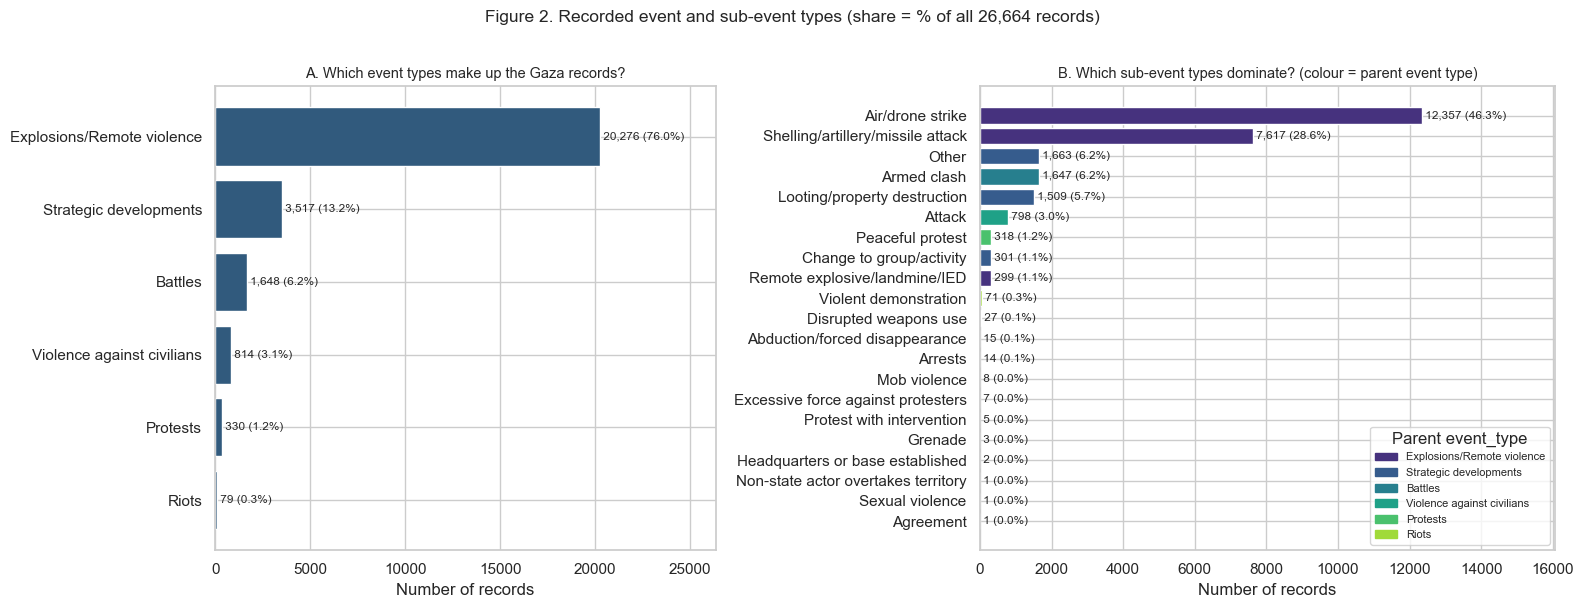

In [15]:
def short(label, n=46):
    label = str(label)
    return label if len(label) <= n else label[: n - 1] + "…"

def barh_counts(ax, counts, total, title, color=BLUE, xlabel="Number of records"):
    """Horizontal count bars (largest on top) labelled with count and share of `total`."""
    counts = counts.sort_values()
    ax.barh([short(i) for i in counts.index], counts.values, color=color)
    for ypos, v in enumerate(counts.values):
        ax.text(v, ypos, f" {v:,} ({v / total:.1%})", va="center", fontsize=8.5)
    ax.set_title(title, fontsize=10.5)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, counts.max() * 1.30)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.15]})
barh_counts(axes[0], master.event_type.value_counts(), len(master),
            "A. Which event types make up the Gaza records?")
type_order = master.event_type.value_counts().index.tolist()
palette = dict(zip(type_order, sns.color_palette("viridis", len(type_order))))
sub_counts = master.sub_event_type.value_counts().sort_values()
axes[1].barh([short(i) for i in sub_counts.index], sub_counts.values,
             color=[palette[parent["first"][i]] for i in sub_counts.index])
for ypos, v in enumerate(sub_counts.values):
    axes[1].text(v, ypos, f" {v:,} ({v / len(master):.1%})", va="center", fontsize=8.5)
axes[1].set_xlim(0, sub_counts.max() * 1.30)
axes[1].set_title("B. Which sub-event types dominate? (colour = parent event type)", fontsize=10.5)
axes[1].set_xlabel("Number of records")
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[t]) for t in type_order]
axes[1].legend(handles, type_order, fontsize=8, loc="lower right", title="Parent event_type")
fig.suptitle("Figure 2. Recorded event and sub-event types (share = % of all 26,664 records)", fontsize=12.5, y=1.01)
plt.tight_layout()
plt.show()

**Question.** Which event types and sub-event types make up the Gaza records? <br>
**Result.** *Explosions/Remote violence* is 76.1% of records (20,276), followed by *Strategic developments* 13.2% (3,517), *Battles* 6.2% (1,648), *Violence against civilians* 3.1% (814), *Protests* 1.2% (330) and *Riots* 0.3% (79). Two sub-types, *Air/drone strike* (12,357; 46.3%) and *Shelling/artillery/missile attack* (7,617; 28.6%), together make up 74.9% of all records. Eleven of the 21 sub-types have fewer than 30 records. By `disorder_type`, 22,746 records are *Political violence*, 3,517 *Strategic developments*, 394 *Demonstrations*, and 7 carry both Political violence and Demonstrations, so the `political_violence` flag covers 22,753 records (85.3%).<br>
**Meaning.** The data is dominated by a few remote-violence categories. This is a class-imbalance problem for any event-type comparison (BQ2) and for Hypothesis B, which tests focal prevalence across event types within political-violence records.<br>
**Limit.** ACLED's `Strategic developments` includes sub-types such as *Looting/property destruction* and *Other*, so the label is not a measure of fighting. Rare categories (Riots, Protests, and the sub-types with a handful of records) will give sparse cells and should be grouped, or tested with a Monte Carlo method.

### 3.8.4 Actors: `actor1`, `actor2`, `inter1`, `inter2`

**Question:** which actor labels recur, how many are blank, and what changes when we look only at focal events?
Actor labels are ACLED's coding, not verified roles. `actor2` blanks are structural: Phase 2 showed they coincide with blank `inter2` and a single-sided interaction label, and the assertion below re-confirms that. We list top labels overall and among focal events (`focal_event == True`).

In [16]:
focal = master[master.focal_event]

actor_overview = pd.DataFrame({
    "actor1": [master.actor1.isna().sum(), master.actor1.nunique()],
    "actor2": [master.actor2.isna().sum(), master.actor2.nunique()],
    "inter1 (actor type)": [master.inter1.isna().sum(), master.inter1.nunique()],
    "inter2 (actor type)": [master.inter2.isna().sum(), master.inter2.nunique()],
}, index=["Missing", "Distinct labels"]).T
actor_overview["Missing (%)"] = (100 * actor_overview.Missing / len(master)).round(2)
display(actor_overview)

only = master.interaction.str.endswith(" only", na=False)
assert master.actor2.isna().equals(master.inter2.isna()) and (~master.actor2.isna() | only).all()
print("Blank actor2 = blank inter2 in every record, and every blank sits on a single-sided ('only') interaction.")

print("\nTop actor1 labels, all events")
display(count_table(master.actor1).head(10))
print("\nTop actor2 labels, all events (blank shown as NaN)")
display(count_table(master.actor2).head(8))
print(f"\nFocal events: {len(focal):,}")
print("Top actor1 labels among focal events")
display(count_table(focal.actor1).head(8))
print("actor2 among focal events:", focal.actor2.value_counts(dropna=False).to_dict())

print("\nActor-type (inter1) counts, all events")
display(count_table(master.inter1))

# Date range of the two Israeli-forces labels: are they versions rather than separate actors?
israel = master[master.actor1.str.startswith("Military Forces of Israel", na=False)]
display(israel.groupby("actor1").event_date.agg(["min", "max", "size"]))

,Missing,Distinct labels,Missing (%)
actor1,0,34,0.00
actor2,8641,41,32.41
inter1 (actor type),0,7,0.00
inter2 (actor type),8641,8,32.41


Blank actor2 = blank inter2 in every record, and every blank sits on a single-sided ('only') interaction.

Top actor1 labels, all events


,Records,Share (%)
Military Forces of Israel (2022-),21629,81.12
Hamas Movement,1942,7.28
Military Forces of Israel (2021-2022),1277,4.79
PIJ: Palestinian Islamic Jihad,622,2.33
Protesters (Palestine),329,1.23
Civilians (Palestine),135,0.51
Sahm Unit,124,0.47
Unidentified Armed Group (Palestine),97,0.36
Al Aqsa Martyrs Brigade,97,0.36
Mujahideen Brigades,81,0.30



Top actor2 labels, all events (blank shown as NaN)


,Records,Share (%)
Civilians (Palestine),13638,51.15
NaN,8641,32.41
Military Forces of Israel (2022-),2933,11.00
Hamas Movement,876,3.29
PIJ: Palestinian Islamic Jihad,294,1.10
Unidentified Armed Group (Palestine),109,0.41
Police Forces of Palestine (2007-) Gaza Strip,41,0.15
Unidentified Communal Militia (Palestine),21,0.08



Focal events: 10,714
Top actor1 labels among focal events


,Records,Share (%)
Military Forces of Israel (2022-),10493,97.94
Sahm Unit,90,0.84
Military Forces of Israel (2021-2022),36,0.34
Hamas Movement,36,0.34
Unidentified Armed Group (Palestine),28,0.26
Unidentified Communal Militia (Palestine),9,0.08
Police Forces of Palestine (2007-) Gaza Strip,7,0.07
Unidentified Clan Militia (Palestine),4,0.04


actor2 among focal events: {'Civilians (Palestine)': 10714}

Actor-type (inter1) counts, all events


,Records,Share (%)
External/Other forces,22922,85.97
Political militia,3146,11.80
Protesters,330,1.24
Civilians,135,0.51
Rioters,79,0.30
Identity militia,38,0.14
State forces,14,0.05


,min,max,size
actor1,,,
Military Forces of Israel (2021-2022),2022-01-01,2022-12-28,1277
Military Forces of Israel (2022-),2022-12-29,2025-09-30,21629
Military Forces of Israel (2022-) Golani Brigade,2025-03-19,2025-04-17,2
Military Forces of Israel (2022-) Special Forces,2023-12-12,2023-12-13,11


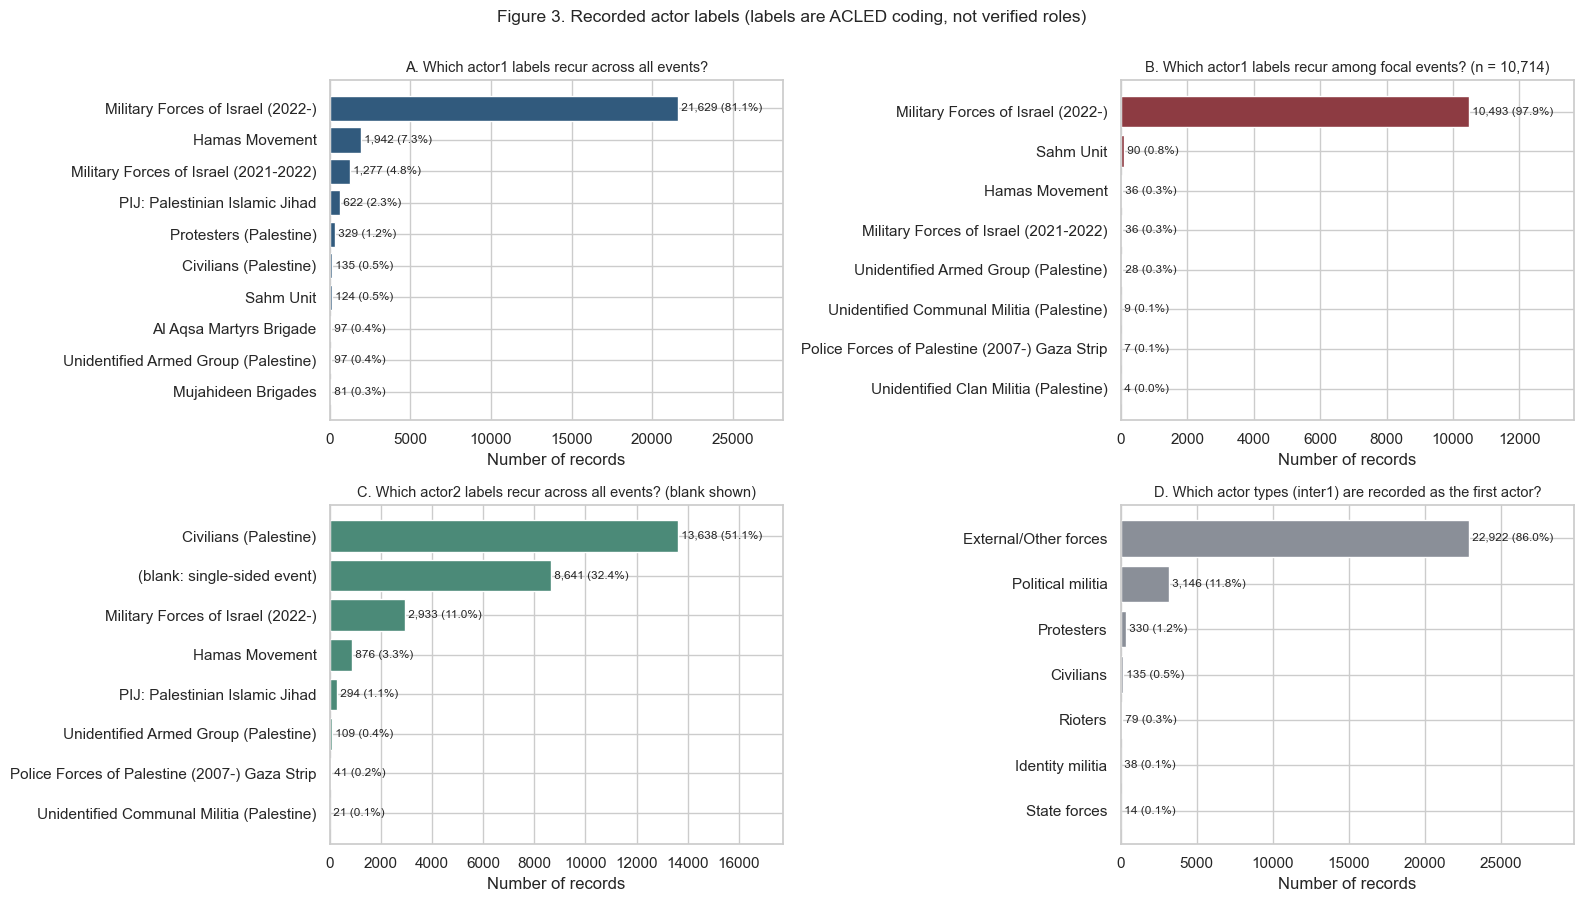

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

barh_counts(axes[0, 0], master.actor1.value_counts().head(10), len(master),
            "A. Which actor1 labels recur across all events?")
barh_counts(axes[0, 1], focal.actor1.value_counts().head(8), len(focal),
            "B. Which actor1 labels recur among focal events? (n = 10,714)", color=RED)

actor2_counts = master.actor2.fillna("(blank: single-sided event)").value_counts().head(8)
barh_counts(axes[1, 0], actor2_counts, len(master),
            "C. Which actor2 labels recur across all events? (blank shown)", color=GREEN)
barh_counts(axes[1, 1], master.inter1.value_counts(), len(master),
            "D. Which actor types (inter1) are recorded as the first actor?", color=GREY)

fig.suptitle("Figure 3. Recorded actor labels (labels are ACLED coding, not verified roles)", fontsize=12.5, y=1.0)
plt.tight_layout()
plt.show()

**Question.** Which actor labels recur across all events and among focal events? <br>
**Result.** `actor1` is never blank (34 labels); `actor2` is blank in 8,641 records (32.4%, structural) and has 41 labels. Across all events, *Military Forces of Israel (2022-)* is the `actor1` label in 21,629 records (81.1%), followed by *Hamas Movement* (1,942; 7.3%), the earlier-dated *Military Forces of Israel (2021-2022)* label (1,277; 4.8%) and *PIJ* (622; 2.3%). The two Israeli-forces labels switch on December 29, 2022 (the 2021–2022 label ends on December 28, 2022 and the 2022- label begins the next day), so they look like date-versioned names, not two different forces. `actor2` is *Civilians (Palestine)* in 13,638 records (51.1%). Among the 10,714 focal events, *Military Forces of Israel (2022-)* is `actor1` in 10,493 (97.9%), with *Sahm Unit* (90), then *Hamas Movement* and the 2021–2022 Israeli-forces label (36 each, tied) and *Unidentified Armed Group (Palestine)* (28). <br>
**Meaning.** Within focal events the `actor1` distribution is almost a single label, and `actor2` is always *Civilians (Palestine)* because the focal rule requires that label. Actor labels therefore separate focal from non-focal events by construction and carry little further information inside the focal group. BQ2 needs event types, notes and dates, not actor labels alone.<br>
**Limit.** Actor labels are coded categories. They do not establish who did what, intent, or responsibility, and the versioned Israeli-forces labels are kept separate (as in Phase 2); merging them is an analyst decision that should be documented.<br>

In [18]:
# Marginal distributions of the three Boolean flags; period comparisons are in Section 3.9.
for col in ["targeting_flagged", "political_violence", "focal_event"]:
    counts = master[col].value_counts(dropna=False).reindex([True, False], fill_value=0)
    table = pd.DataFrame({"count": counts, "share_pct": (100 * counts / len(master)).round(2)})
    print(f"\n{col}: denominator = all {len(master):,} Gaza event records")
    display(table)


targeting_flagged: denominator = all 26,664 Gaza event records


,count,share_pct
True,10732,40.25
False,15932,59.75



political_violence: denominator = all 26,664 Gaza event records


,count,share_pct
True,22753,85.33
False,3911,14.67



focal_event: denominator = all 26,664 Gaza event records


,count,share_pct
True,10714,40.18
False,15950,59.82


**Flag interpretation.** These are all-period marginal counts. `targeting_flagged` is the recorded ACLED targeting flag, `political_violence` defines the denominator used later, and `focal_event` applies the project's documented flag-plus-actor rule. Period-specific comparisons belong in Section 3.9.

### 3.8.5 Quality codes: `geo_precision` and `time_precision`

**Question:** how precisely are locations and dates recorded, and does the land focal table differ from the full master?
These are categorical codes (1, 2, 3), not measurements. We show them for the event master and the land focal incident table, and split `geo_precision` by period.

In [19]:
def code_share(frame, col):
    return (frame[col].value_counts(normalize=True).sort_index() * 100).round(2)

prec = pd.DataFrame({
    "geo_precision: master (n)": master.geo_precision.value_counts().sort_index(),
    "geo_precision: master (%)": code_share(master, "geo_precision"),
    "geo_precision: land focal incidents (n)": incidents.geo_precision.value_counts().sort_index(),
    "geo_precision: land focal incidents (%)": code_share(incidents, "geo_precision"),
})
display(prec)
tprec = pd.DataFrame({
    "time_precision: master (n)": master.time_precision.value_counts().sort_index(),
    "time_precision: master (%)": code_share(master, "time_precision"),
    "time_precision: land focal incidents (n)": incidents.time_precision.value_counts().sort_index(),
    "time_precision: land focal incidents (%)": code_share(incidents, "time_precision"),
})
display(tprec)
by_period_prec = pd.crosstab(master.period, master.geo_precision, normalize="index").mul(100).round(1)
by_period_prec.columns = [f"geo_precision {i} (%)" for i in by_period_prec.columns]
print("geo_precision by period (share of each period's records):")
display(by_period_prec.loc[[BEFORE, AFTER]])
print("geo_precision_1 =", f"{master.geo_precision_1.mean():.1%} of master;", f"{incidents.geo_precision_1.mean():.1%} of land focal incidents")
print("time_precision_1 =", f"{master.time_precision_1.mean():.1%} of master")

,geo_precision: master (n),geo_precision: master (%),geo_precision: land focal incidents (n),geo_precision: land focal incidents (%)
1,14313,53.68,7576,71.59
2,12231,45.87,2976,28.12
3,120,0.45,31,0.29


,time_precision: master (n),time_precision: master (%),time_precision: land focal incidents (n),time_precision: land focal incidents (%)
1,26451,99.20,10541,99.60
2,188,0.71,37,0.35
3,25,0.09,5,0.05


geo_precision by period (share of each period's records):


,geo_precision 1 (%),geo_precision 2 (%),geo_precision 3 (%)
period,,,
"Before Oct 7, 2023",20.0,79.5,0.5
"Oct 7, 2023 onward",56.8,42.8,0.4


geo_precision_1 = 53.7% of master; 71.6% of land focal incidents
time_precision_1 = 99.2% of master


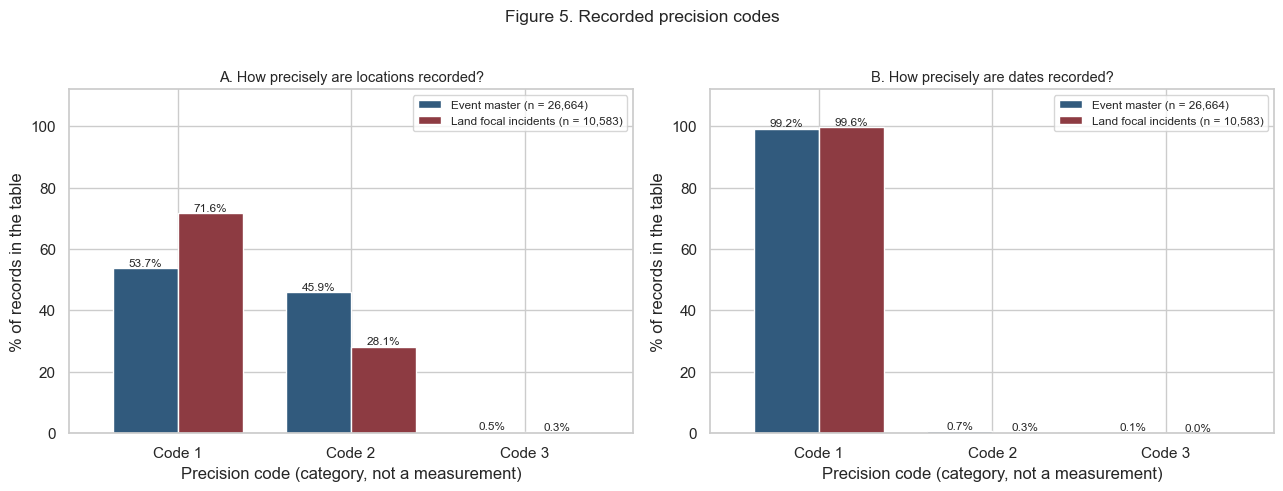

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col, title in [(axes[0], "geo_precision", "A. How precisely are locations recorded?"),
                       (axes[1], "time_precision", "B. How precisely are dates recorded?")]:
    shares = pd.DataFrame({"Event master (n = 26,664)": master[col].value_counts(normalize=True).sort_index() * 100,
                           "Land focal incidents (n = 10,583)": incidents[col].value_counts(normalize=True).sort_index() * 100})
    shares.index = [f"Code {i}" for i in shares.index]
    shares.plot.bar(ax=ax, color=[BLUE, RED], rot=0, width=0.75)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", fontsize=8.5)
    ax.set_title(title, fontsize=10.5)
    ax.set_ylabel("% of records in the table")
    ax.set_xlabel("Precision code (category, not a measurement)")
    ax.set_ylim(0, 112)
    ax.legend(fontsize=8.5)
fig.suptitle("Figure 5. Recorded precision codes", fontsize=12.5, y=1.02)
plt.tight_layout()
plt.show()

**Question.** How precisely are locations and dates recorded?<br>
**Result.** Dates are almost always precise: `time_precision` = 1 in 99.2% of the master (26,451 records; 188 are code 2 and 25 are code 3). Locations are not: `geo_precision` = 1 in 53.7% of records (14,313), code 2 in 45.9% (12,231) and code 3 in 0.45% (120; about 0.5% to one decimal place). In the land focal incidents, code 1 is higher at 71.6% (7,576 of 10,583). Precision also differs sharply by period: only 20.0% of pre-Oct 7 records are code 1, against 56.8% from Oct 7 onward.<br>
**Meaning.** The `geo_precision_1` subset is a real restriction: it keeps 71.6% of the focal incidents and a different mix of places. The much lower share of precise locations before Oct 7 also means maps and clusters from the two periods are not equally well located.<br>
**Limit.** Precision reflects how the location was documented, not where events happened. A pattern that changes with the precision restriction may be a documentation effect, and the Phase 4 sensitivity run has to show both views.

### 3.8.6 Area and time: `admin2`, `location`, `period`, `year`, `month_start`, `week_start`

**Question:** where and when are records logged?
We count records by district (the four with no district stay visible), summarize the monthly and weekly record counts, and mark October 7, 2023. These are record counts at the event level, not rates.

In [21]:
admin2_counts = master.admin2.fillna("(missing district)").value_counts()
admin_tbl = admin2_counts.rename("Records").to_frame()
admin_tbl["Share of all events (%)"] = (100 * admin_tbl.Records / len(master)).round(2)
admin_tbl["Share of known-district events (%)"] = (100 * admin_tbl.Records / master.admin2.notna().sum()).round(2)
admin_tbl.loc["(missing district)", "Share of known-district events (%)"] = np.nan
display(admin_tbl)
print("Missing-district records (all coast-coded in Phase 2):", int(master.district_missing.sum()))
print(f"Coast-coded locations: {master.coastal_location.sum():,} records ({master.coastal_location.mean():.1%}); "
      f"distinct location labels: {master.location.nunique()}")

display(master.groupby("year").size().rename("Records").to_frame().assign(
    **{"Share (%)": lambda d: (100 * d.Records / len(master)).round(2)}))

monthly = master.groupby("month_start").size()
weekly_n = master.groupby("week_start").size()
print(f"\nDistinct calendar months: {monthly.size} | distinct Saturday-start weeks: {weekly_n.size}")
display(pd.DataFrame({"Records per month": monthly.describe().round(1),
                      "Records per week": weekly_n.describe().round(1)}).T)
print("Peak month:", monthly.idxmax().strftime("%Y-%m"), f"({monthly.max():,} records)")
print("Peak week:", weekly_n.idxmax().date(), f"({weekly_n.max():,} records)")
print("Median monthly records, before vs from Oct 2023:",
      int(monthly[monthly.index < "2023-10-01"].median()), "vs", int(monthly[monthly.index >= "2023-10-01"].median()))

,Records,Share of all events (%),Share of known-district events (%)
Gaza City,8036,30.14,30.14
Khan Yunis,6005,22.52,22.52
Deir El Balah,4781,17.93,17.93
North Gaza,4303,16.14,16.14
Rafah,3535,13.26,13.26
(missing district),4,0.02,NaN


Missing-district records (all coast-coded in Phase 2): 4
Coast-coded locations: 701 records (2.6%); distinct location labels: 117


,Records,Share (%)
year,,
2022,1430,5.36
2023,4449,16.69
2024,12823,48.09
2025,7962,29.86



Distinct calendar months: 45 | distinct Saturday-start weeks: 196


,count,mean,std,min,25%,50%,75%,max
Records per month,45.0,592.5,499.0,46.0,115.0,637.0,1044.0,1466.0
Records per week,196.0,136.0,117.5,3.0,25.0,80.0,241.2,367.0


Peak month: 2023-12 (1,466 records)
Peak week: 2023-10-28 (367 records)
Median monthly records, before vs from Oct 2023: 109 vs 1034


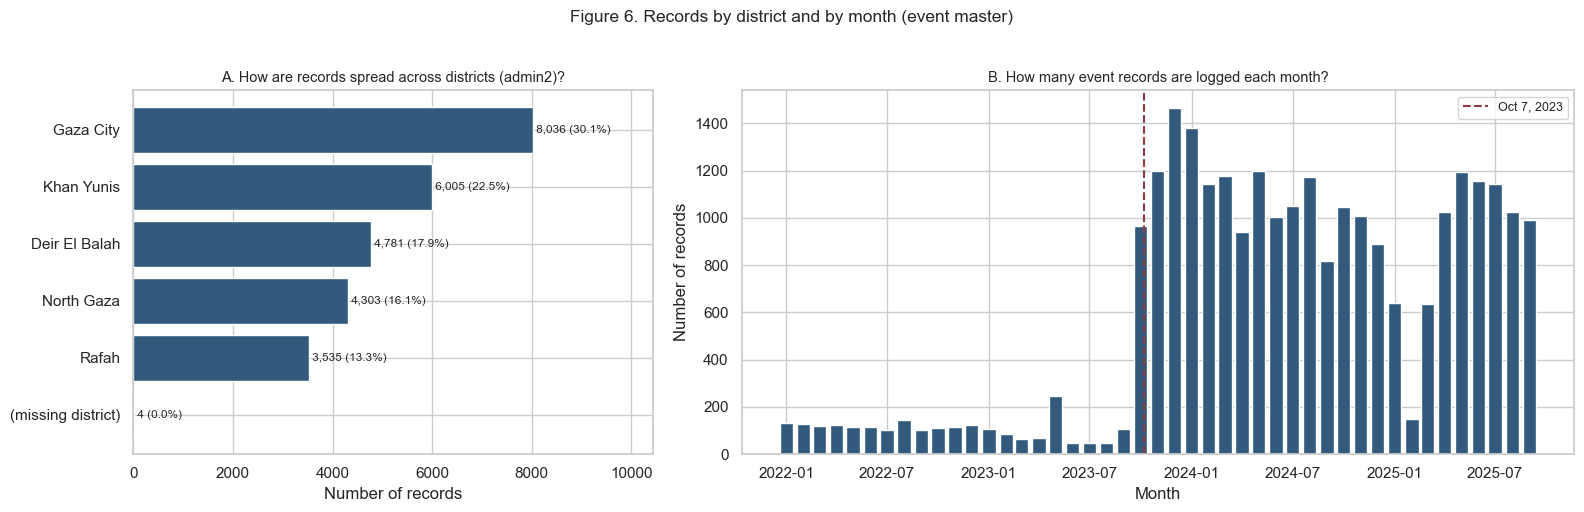

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.6]})
barh_counts(axes[0], admin2_counts, len(master), "A. How are records spread across districts (admin2)?")
axes[1].bar(monthly.index, monthly.values, width=24, color=BLUE)
axes[1].axvline(cutoff, color=RED, ls="--", lw=1.5, label="Oct 7, 2023")
axes[1].set_title("B. How many event records are logged each month?", fontsize=10.5)
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of records")
axes[1].legend(fontsize=9)
fig.suptitle("Figure 6. Records by district and by month (event master)", fontsize=12.5, y=1.02)
plt.tight_layout()
plt.show()

**Question.** How are records spread across districts, and how many are logged each month? <br>
**Result.** Records are logged in five districts: Gaza City 8,036 (30.1%), Khan Yunis 6,005 (22.5%), Deir El Balah 4,781 (17.9%), North Gaza 4,303 (16.1%) and Rafah 3,535 (13.3%); 4 records have no district (all coast-coded) and 701 records (2.6%) have a coast-coded location label. By year, 2022 has 1,430 records, 2023 has 4,449, 2024 has 12,823 (48.1%), and 2025 (January to September) has 7,962. The monthly median is 109 records before October 2023 and 1,034 from October 2023, with a peak of 1,466 in December 2023 and a peak week of 367 records (week starting October 28, 2023). Two months are notable departures from their immediate neighbors: May 2023 (248 records, against 69 in April and 49 in June) and February 2025 (150 records, against 638 in January and 637 in March). <br>
**Meaning.** Records concentrate in Gaza City, but no district is negligible. The monthly series changes substantially around October 2023 and contains a marked February 2025 trough relative to adjacent months. These are descriptive patterns only; the monthly counts do not establish why the changes occurred. Period, time and district should be considered in later comparisons. <br>
**Limit.** Record counts reflect both activity and reporting coverage, which can change over time and place. The four missing-district events remain in Gaza-wide totals and are excluded only from district summaries. May 2023 and February 2025 are descriptive observations; this table does not explain them.


## 3.9 Bivariate analysis — how do groups compare?

**Source table:** `master` unless the comparison is explicitly weekly or spatial. Start with Phase 1 questions: before/after period differences, event-type composition, actor/event profiles, severity, and precision. Use counts and rates together when group sizes differ.

For every share, state the denominator. For actor comparisons, describe recorded labels and consult notes before assigning actor roles. These are exploratory comparisons; an association is not a causal effect.

,events,political_events,focal_events,focal_share_of_all_events,focal_share_of_political_events
event_type,,,,,
Explosions/Remote violence,20276,20276,9906,0.488558,0.488558
Violence against civilians,814,814,808,0.992629,0.992629
Battles,1648,1648,0,0.000000,0.000000
Protests,330,7,0,0.000000,0.000000
Riots,79,8,0,0.000000,0.000000
Strategic developments,3517,0,0,0.000000,NaN


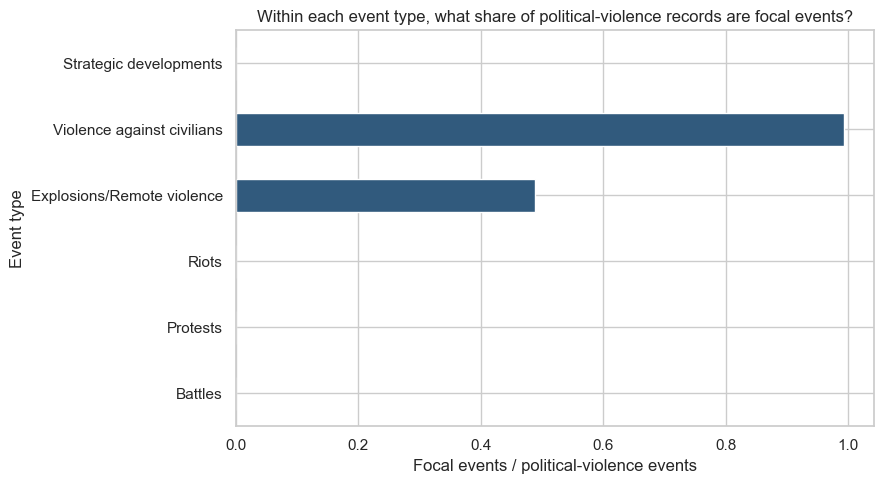

In [23]:
# Example: event-type denominators and focal-event counts/shares.
event_type_summary = master.groupby("event_type", dropna=False).agg(
    events=("event_id_cnty", "size"),
    political_events=("political_violence", "sum"),
    focal_events=("focal_event", "sum"),
)
event_type_summary["focal_share_of_all_events"] = event_type_summary.focal_events / event_type_summary.events
event_type_summary["focal_share_of_political_events"] = (
    event_type_summary.focal_events / event_type_summary.political_events.replace(0, np.nan)
)
display(event_type_summary.sort_values("focal_events", ascending=False))

ax = event_type_summary.sort_values("focal_share_of_political_events")["focal_share_of_political_events"].plot(
    kind="barh", figsize=(9, 5), color="#315A7D"
)
ax.set_title("Within each event type, what share of political-violence records are focal events?")
ax.set_xlabel("Focal events / political-violence events")
ax.set_ylabel("Event type")
plt.tight_layout()
plt.show()

# Interpretation: [Which event types have the largest focal shares? How do counts and denominators affect the comparison?]

### Interpretation — event type and focal-event share

**Observed pattern:** [Identify event types with high counts and/or high within-type focal shares. Quote their denominators.]  
**Why it matters:** [Explain how this helps answer BQ2 and what should be reviewed in event notes.]  
**Limit:** [State how category size, coding, or missingness affects the comparison.]

## 3.10 Grouped, temporal, and spatial analysis — where and when do patterns occur?

This section changes the unit of analysis. `gaza_weekly` is one Gaza-wide week; `district_weekly` is one known district-week; `incidents` is one post–October 7 land focal incident. Keep each figure tied to its table and unit.

For temporal figures, distinguish event counts from shares and mark the incomplete final week. For district comparisons, show denominators and keep unknown-district records in Gaza-wide totals. For spatial figures, compare precision subsets on the same map extent and describe recorded concentrations rather than exact attack points.

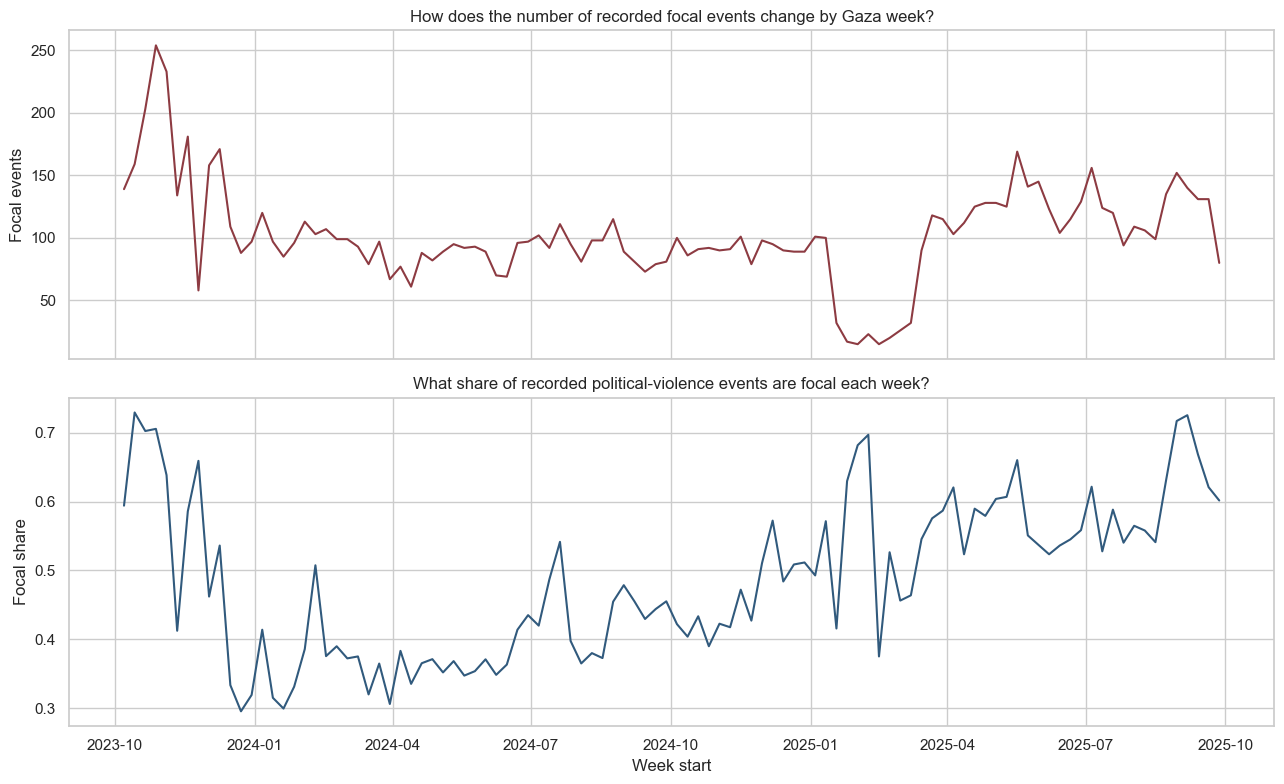

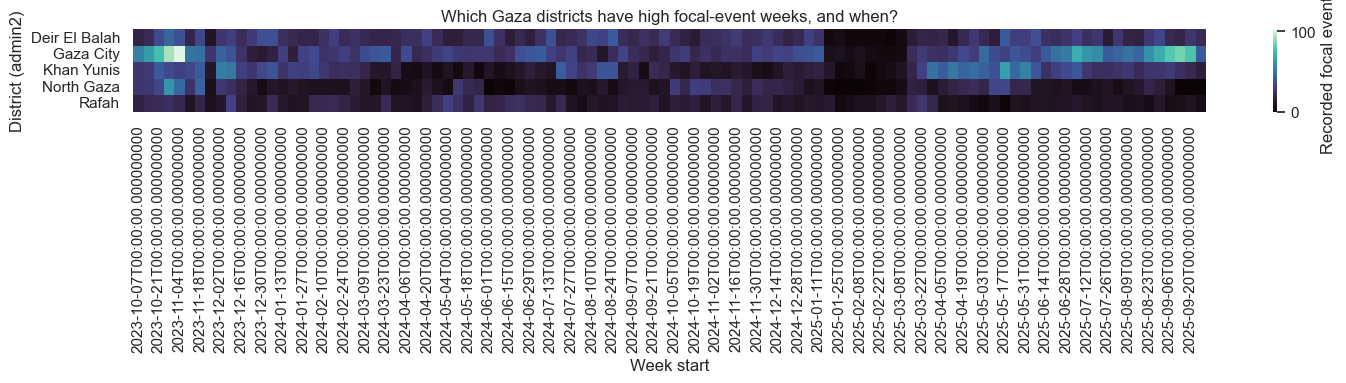

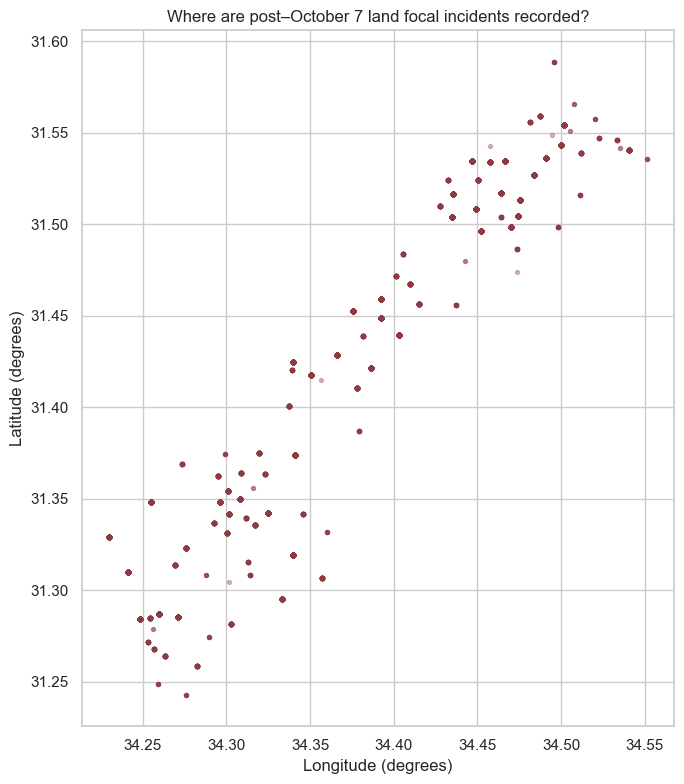

In [24]:
# Weekly and spatial examples; count, share, and coordinate plots have different units.
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(gaza_weekly.week_start, gaza_weekly.focal_events, color="#8D3B42")
axes[0].set_title("How does the number of recorded focal events change by Gaza week?")
axes[0].set_ylabel("Focal events")
axes[1].plot(gaza_weekly.week_start, gaza_weekly.focal_share, color="#315A7D")
axes[1].set_title("What share of recorded political-violence events are focal each week?")
axes[1].set_ylabel("Focal share")
axes[1].set_xlabel("Week start")
plt.tight_layout()
plt.show()

# District-week heatmap: select complete weeks and order districts explicitly.
heat = district_weekly.pivot(index="admin2", columns="week_start", values="focal_events")
plt.figure(figsize=(15, max(4, .45 * len(heat))))
sns.heatmap(heat, cmap="mako", cbar_kws={"label": "Recorded focal events"})
plt.title("Which Gaza districts have high focal-event weeks, and when?")
plt.xlabel("Week start")
plt.ylabel("District (admin2)")
plt.tight_layout()
plt.show()

# Spatial scatter; map projection/basemap may be added if available and sourced.
plt.figure(figsize=(7, 8))
plt.scatter(incidents.longitude, incidents.latitude, s=8, alpha=.35, color="#8D3B42")
plt.title("Where are post–October 7 land focal incidents recorded?")
plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
plt.tight_layout()
plt.show()

### Interpretation prompts for grouped, temporal, and spatial figures

**Weekly trend:** [Describe sustained changes, spikes, zero-denominator weeks, and incomplete coverage.]  
**District-week heatmap:** [Identify visible concentration or persistence; distinguish high volume from high share.]  
**Spatial view:** [Describe coordinate concentration and precision limits; do not infer exact boundaries or safety.]

## 3.11 Hypothesis testing plan and report

Set the hypothesis before looking at the test result. Use **at least two** tests aligned with the business questions. Report the test statistic, p-value, effect size, assumptions, and a plain-language conclusion. Treat tests as exploratory because events can be related by time and place.

### Hypothesis A — before/after focal share
- **Question:** Did the share of political-violence event records classified as focal differ between the two periods?
- **H0:** Period and focal-event status are independent among political-violence records.
- **H1:** Period and focal-event status are associated.
- **Table:** Rows = period; columns = focal yes/no; restrict denominator to `political_violence == True`.
- **Candidate test:** Chi-square independence if expected counts are adequate; exact/Monte Carlo alternative if not. Report Cramér’s V.
- **Caution:** Periods have unequal duration, and earlier focal counts may be sparse. Show counts and per-week context; do not imply period caused the difference.

### Hypothesis B — event type and focal status
- **Question:** Does focal-event prevalence vary by recorded event type?
- **H0:** Event type and focal-event status are independent among political-violence records.
- **H1:** At least one event type has a different focal-event prevalence.
- **Table:** Rows = event type; columns = focal yes/no; denominator restricted to political-violence records.
- **Candidate test:** Chi-square independence; use Monte Carlo resampling if expected counts are small. Report Cramér’s V and within-type rates.
- **Caution:** The test is an association in this export. It does not establish event-type effects or causal relationships.

### Test report table — fill after running

| Hypothesis | Test and assumptions checked | Statistic | p-value | Effect size | Plain-language conclusion / limitation |
|---|---|---:|---:|---:|---|
| A: period × focal status | [Fill] | [Fill] | [Fill] | [Fill] | [Fill] |
| B: event type × focal status | [Fill] | [Fill] | [Fill] | [Fill] | [Fill] |

Use a preselected significance threshold (for example, α = 0.05) and disclose multiple exploratory comparisons if you run additional tests.

In [25]:
# Test scaffold: use political-violence records as the denominator; inspect expected counts before choosing the final procedure.
from scipy.stats import chi2_contingency

political = master.loc[master.political_violence].copy()
period_table = pd.crosstab(political.period, political.focal_event)
print("Period × focal status")
display(period_table)
period_chi = chi2_contingency(period_table, correction=False)
print("Chi-square:", period_chi.statistic, "p:", period_chi.pvalue)
print("Expected counts:")
display(pd.DataFrame(period_chi.expected_freq, index=period_table.index, columns=period_table.columns))

# If expected counts are small, do not blindly report this asymptotic p-value;
# use a justified exact/Monte Carlo procedure and document the method and seed.
# Repeat the same diagnostic for event_type × focal_event before interpreting.

Period × focal status


focal_event,False,True
period,,
"Before Oct 7, 2023",326,63
"Oct 7, 2023 onward",11713,10651


Chi-square: 151.59751207686466 p: 7.758781647612591e-35
Expected counts:


focal_event,False,True
period,,
"Before Oct 7, 2023",205.826528,183.173472
"Oct 7, 2023 onward",11833.173472,10530.826528


## 3.12 Key findings and Phase 4 plan

### Key insights (final submission: 5–8 evidence-backed bullets)
1. **[Insight]** [Metric/figure/table and which business question it answers.]  
2. **[Insight]** [Evidence and limitation.]  
3. **[Insight]** [Evidence and limitation.]  
4. **[Insight]** [Evidence and limitation.]  
5. **[Insight]** [Evidence and limitation.]  
6. **[Optional insight]** [...]  
7. **[Optional insight]** [...]  
8. **[Optional insight]** [...]

### Phase 4 modeling plan

| Proposed technique | EDA evidence that supports it | Inputs / target | Baseline or comparison | Risks / sensitivity checks |
|---|---|---|---|---|
| DBSCAN spatial clustering | [Concentration, repeated locations, precision pattern] | Land focal-event coordinates in radians; Haversine distance | District-level count summaries | Vary epsilon/min_samples; compare precision-1 subset; interpret clusters as recorded concentrations. |
| Weekly anomaly detection | [Visible spikes/persistence and historical distribution] | District-week focal counts plus eligible prior-week history | Trailing median/MAD rule | Chronological evaluation; incomplete weeks and sparse history; compare with Isolation Forest if retained. |

Only retain techniques supported by the EDA and Phase 1 plan. Record any revisions to the modeling questions and why the revision follows from evidence.

## 3.13 Limitations, reproducibility, and references

### Limitations to report
- ACLED is a recorded-event dataset and may underrepresent events; reporting coverage can change across time and place.
- Fatality totals are event-level reported values and do not automatically identify civilian fatalities.
- Actor, targeting, location, and precision fields reflect the source’s coding and may be incomplete or approximate.
- Observations may be related across time and geography, limiting simple independence assumptions in statistical tests.
- Descriptive differences and statistical associations do not establish causation, intent, or legal classification.

### Reproducibility checklist
- [ ] Phase 2 exports are loaded from `data/processed` and source snapshot is identified.
- [ ] Date parsing and precision category restoration are explicit.
- [ ] Every subset/filter is described, including coast exclusion and district missingness.
- [ ] Randomized tests include a fixed seed and number of resamples.
- [ ] Notebook runs from top to bottom and all charts/tables reconcile to their analysis table.

### References
- Group 7, *Phase 1 — Dataset Selection and Business Problem*.
- Group 7, *Phase 2 — Data Preprocessing*.
- *DS312 Final Project Guide*, Phase 3: Exploratory Data Analysis (EDA).
- ACLED, *Codebook* and the documented event-level export snapshot.